# 🚧 IN PROGRESING ..... 🚧

## First Semester:

**🤷🏾‍♂️ What will I do?**
* **Problem Definition**
* **Literature Review**
* **[GitHub Setup](https://github.com/MattheuSxS/CCT_ST_CA_01_20S)**
* **Exploratory Data Analysis (EDA)**
* **Initial Preprocessing.**

### 🏦 Business Problem Definition

**Information about the selected dataset**

This research aimed at the case of customers' default payments in Taiwan and compares the predictive accuracy of probability of default among six data mining methods. From the perspective of risk management, the result of predictive accuracy of the estimated probability of default will be more valuable than the binary result of classification - credible or not credible clients. Because the real probability of default is unknown, this study presented the novel Sorting Smoothing Method to estimate the real probability of default. With the real probability of default as the response variable (Y), and the predictive probability of default as the independent variable (X), the simple linear regression result (Y = A + BX) shows that the forecasting model produced by artificial neural network has the highest coefficient of determination; its regression intercept (A) is close to zero, and regression coefficient (B) to one. Therefore, among the six data mining techniques, artificial neural network is the only one that can accurately estimate the real probability of default.

**🚨 Problem Definition and Motivation**

* **Domain**: Business (Financial / Banking Risk)
* **Problem Type**: Supervised Machine Learning – Binary Classification
* **Target Variable ($Y$)**: Default of Credit Card Clients (`Default` = 1 | `No Default` = 0)

&gt; `Credit card default payment` poses a significant financial risk to banking institutions, leading to substantial credit losses, reduced liquidity, and increased operational costs associated with debt recovery. When cardholders fail to fulfill their payment obligations, financial institutions face immediate revenue impairment and higher capital reserve requirements to hedge against uncollectible debts.

&gt; Traditionally, credit risk assessment models relied on static scoring methods; however, these approaches often fail to dynamically capture changing customer payment behaviors over time. The selected dataset from the UCI Machine Learning Repository addresses this challenge by tracking `30,000` credit card clients in Taiwan, capturing demographic features, credit limits, and detailed monthly payment histories over a six-month period (April to September 2005).

&gt; Data analytics and predictive modelling offer a strategic solution to this business problem by enabling accurate estimation of default probability. By leveraging machine learning algorithms on historical behavioral patterns, financial institutions can proactively identify high-risk clients, dynamically adjust credit limits, optimize credit collection strategies, and minimize non-performing loans while protecting organizational profitability.

**🎯 Objectives:**

* **Data Pre-processing & Feature Scaling [ If necessary ]:** Clean the dataset, handle target encoding (`Default` = 1, `No Default` = 0)

* **Model Development:** Implement at least two distinct supervised classification algorithms (**[XGBoost](https://xgboost.readthedocs.io/en/stable/)** and **[Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)**) to predict default probabilities.

* **Multi-Split Performance Evaluation:** Evaluate model accuracy and stability across distinct training set sizes (e.g., **15%**, and **30%**) using **Cross-Validation** techniques to analyze how restricted training data impacts learning stability and variance.

* **Hyperparameter Optimization:** Apply `GridSearchCV` on selected model pipelines to systematically tune key hyperparameters (e.g., `learning_rate`, `colsample_bytree`, `max_depth` for XGBoost ~~ `n_estimators`, `max_depth` for Random Forest).

* **Comprehensive Metric Assessment:** Evaluate predictions using a full suite of classification metrics, including **Accuracy**, **Precision**, **Recall (Sensitivity)**, **F1-Score**, **ROC-AUC**, and **Confusion Matrix**. In a financial risk context, primary emphasis is placed on maximizing **Recall** to minimize critical **False Negatives** (failing to identify defaulting clients).

* **Comparative Analysis & Generalization:** Interpret model outcomes, evaluate feature importance rankings, and discuss trade-offs regarding **overfitting**, **underfitting**, and model generalizability.


**📈 Expected Benefits**

* **Financial Loss Mitigation:** Significantly reduce non-performing loans (NPLs) by identifying potential defaults prior to bill due dates.
* **Proactive Risk Management:** Enable credit risk teams to dynamically adjust credit limits, offer tailored restructuring plans, or initiate early intervention workflows.
* **Automated Decision-Making:** Standardize and accelerate credit risk evaluation across large customer portfolios, reducing operational costs and manual review overhead.

### 🛂 Importing Packages
This is the workspace preparation phase. Here, we load all the necessary Python tools and libraries (such as Pandas for data manipulation, Scikit-learn for modeling, and Matplotlib/Seaborn for visualizations) that will be used throughout the project.

In [33]:
import math
import logging
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
from typing import List, Dict
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.metrics import confusion_matrix, classification_report

In [34]:
logging.basicConfig(
    format=("%(asctime)s | %(levelname)s | File_name ~> %(module)s.py "
            "| Function ~> %(funcName)s | Line ~~> %(lineno)d  ~~>  %(message)s"),
    level=logging.INFO
)

In [35]:
# Display settings
sns.set_style('whitegrid')
%matplotlib inline

In [36]:
%reload_ext watermark
%watermark --author "Matheus DoS S. Silva"
%watermark --email "2026438@student.cct.ie"
%watermark --github_username "MattheuSxS"
%watermark --date
%watermark --python
%watermark --iversions

Author: Matheus DoS S. Silva

Email: 2026438@student.cct.ie

Github username: MattheuSxS

Date: 2026-10-12

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

logging   : 0.5.1.2
matplotlib: 3.11.2
numpy     : 2.5.3
pandas    : 3.0.6
seaborn   : 0.13.2
sklearn   : 1.9.1
ucimlrepo : 0.0.7
xgboost   : 3.4.1



### 🔄 Loading and Understanding the Data

This is the first encounter with the project's raw material. We load the data from a source (in our case, a CSV file) into a Pandas DataFrame and perform an initial check to understand its structure.

The download_dataset() function is responsible for loading the dataset used in the Machine Learning project. 
* **1 ~~>** It first checks whether the dataset already exists locally in the ../data directory.
* **2 ~~>** If the file is not found, it attempts to download the dataset from the UC Irvine Machine Learning Repository using the fetch_ucirepo function.
* **3 ~~>** If this method fails, it uses the UCI URL as a fallback.
 
Once the dataset is available, the function loads it into a Pandas DataFrame and returns it for further data analysis and Machine Learning processing. The function also includes logging and exception handling to provide information about the download and loading process.

In [37]:
def download_dataset() -> pd.DataFrame:
    data_dir = Path("../data")
    dataset_file = data_dir / "data.xls"

    data_dir.mkdir(parents=True, exist_ok=True)

    try:
        if not dataset_file.exists():

            logging.warning("📥 Dataset not found. Downloading from UC Irvine Machine Learning Repository...")

            try:
                data_dict = fetch_ucirepo(id=350) 
                df = data_dict["data"]["features"]
                df["Diagnosis"] = data_dict["data"]["targets"]

                return df

            except Exception as e:
                column_list = \
                    ["ID", "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE", "PAY_0",
                     "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6", "BILL_AMT1", "BILL_AMT2",
                     "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6", "PAY_AMT1", "PAY_AMT2",
                     "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6", "default payment next month"]
                return pd.read_csv("https://archive.ics.uci.edu/static/public/350/data.csv", sep=",")
                
        else:
            logging.info(f"✅ Dataset already exists: {dataset_file}")

        return  pd.read_excel(io = dataset_file, header=1)

    except Exception as e:
        logging.error(f"❌ Failed to download or read the dataset: {e}")

In [38]:
df = download_dataset()

2026-10-12 11:20:49,220 | INFO | File_name ~> 4269813254.py | Function ~> download_dataset | Line ~~> 28  ~~>  ✅ Dataset already exists: ../data/data.xls


In [39]:
# logging.info(f" Shape of DataSet Breast Cancer Wisconsin: {df.shape}")
print(f" Shape of DataSet Breast Cancer Wisconsin: {df.shape}")

 Shape of DataSet Breast Cancer Wisconsin: (30000, 25)


In [40]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [41]:
df.sample(3)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
6615,6616,60000,1,3,2,34,-1,-1,-1,-1,...,326,476,326,326,326,326,476,326,326,1
16125,16126,30000,2,2,1,34,2,2,0,0,...,18473,19763,19306,0,1620,1350,1600,0,1630,1
11444,11445,20000,2,2,2,27,0,0,-1,2,...,26644,26079,27941,0,26373,1000,0,2300,1200,0


In [42]:
df.tail(5)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
29995,29996,220000,1,3,1,39,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,29997,150000,1,3,2,43,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,29998,30000,1,2,2,37,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,29999,80000,1,3,1,41,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1
29999,30000,50000,1,2,1,46,0,0,0,0,...,36535,32428,15313,2078,1800,1430,1000,1000,1000,1


### 🕵🏾 Exploratory Data Analysis (EDA)

The investigation phase. Here, we "dive" into the data to uncover patterns, anomalies, and financial insights. We use statistical summaries and visual charts (such as analyzing credit limit distributions, monthly payment track records, and the target class imbalance between defaulting vs. non-defaulting clients) to understand the dataset's characteristics before making any modifications or transformations.

In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [44]:
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [45]:
# Check for null fields
null_columns = []
for column, value in zip(df.columns, df.isnull().sum()):
    if value > 0:
        logging.warning(f"There are ~~> {value} <~~ null values in the **{column}** column")
        null_columns.append(column)

In [46]:
def default_plot(
    dataset: pd.DataFrame,
    column: str,
    ax: plt.Axes
):
    sns.countplot(
        x=column,
        data=dataset,
        hue=column,
        palette="ch:s=.25,rot=-.25",
        legend=False,
        ax=ax
    )

    ax.set_title(
        f"Distribution of people for {column}",
        fontsize=12,
        fontweight="bold",
        pad=10
    )

    ax.set_xlabel(column, fontsize=10)
    ax.set_ylabel("Number of Samples", fontsize=10)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%d",
            padding=4,
            fontsize=9,
            fontweight="bold"
        )

    sns.despine(ax=ax)

**🎯 Notes:**

* **Gender:** [ 1 = male; 2 = female ].
* **Education:** [ 1 = graduate school; 2 = university; 3 = high school; 4 = others ].
* **Marital status:** [ 1 = married; 2 = single; 3 = others ].

In [54]:
df_copy = df.copy()

df_copy['default payment next month'] = (
    df['default payment next month']
        .map({
            0: "Non Default",
            1: "Default"
        }).fillna("Others"))

df_copy['SEX'] = (
    df['SEX']
        .map({
            1: "Male",
            2: "Female"
        }).fillna("Others"))

df_copy['EDUCATION'] = (
    df['EDUCATION']
        .map({
            1: "Graduate School",
            2: "university",
            3: "High School",
            4: "Others"
        }).fillna("Others"))

df_copy["MARRIAGE"] = (
    df["MARRIAGE"]
    .map({
        1: "Married",
        2: "Single",
        3: "Others"
    }).fillna("Others"))

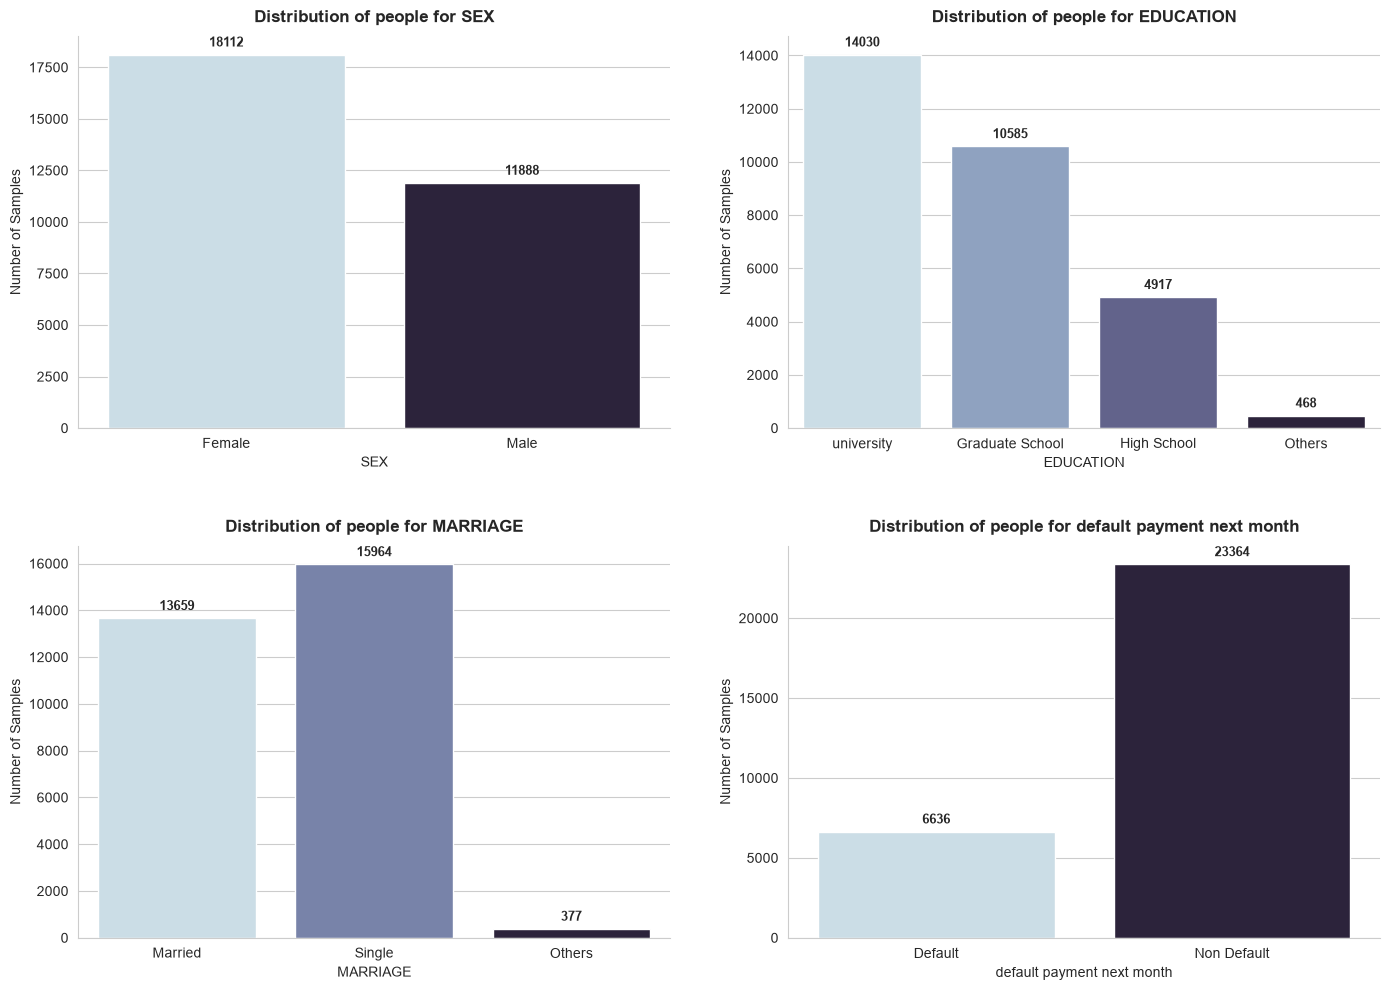

In [63]:
columns = ["SEX", "EDUCATION", "MARRIAGE", "default payment next month"]

n_cols = 2
n_rows = math.ceil(len(columns) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(14, 5 * n_rows)
)

axes = axes.flatten()

for i, column in enumerate(columns):
    default_plot(
        dataset=df_copy,
        column=column,
        ax=axes[i]
    )


for i in range(len(columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
fig.subplots_adjust(wspace=0.2, hspace=0.3)
plt.show()

**The beginning of everything**

Correlation analysis was initially used to identify relationships between features and the target variable and to detect highly correlated features. Feature selection was then performed to reduce redundancy and identify the most relevant predictors.

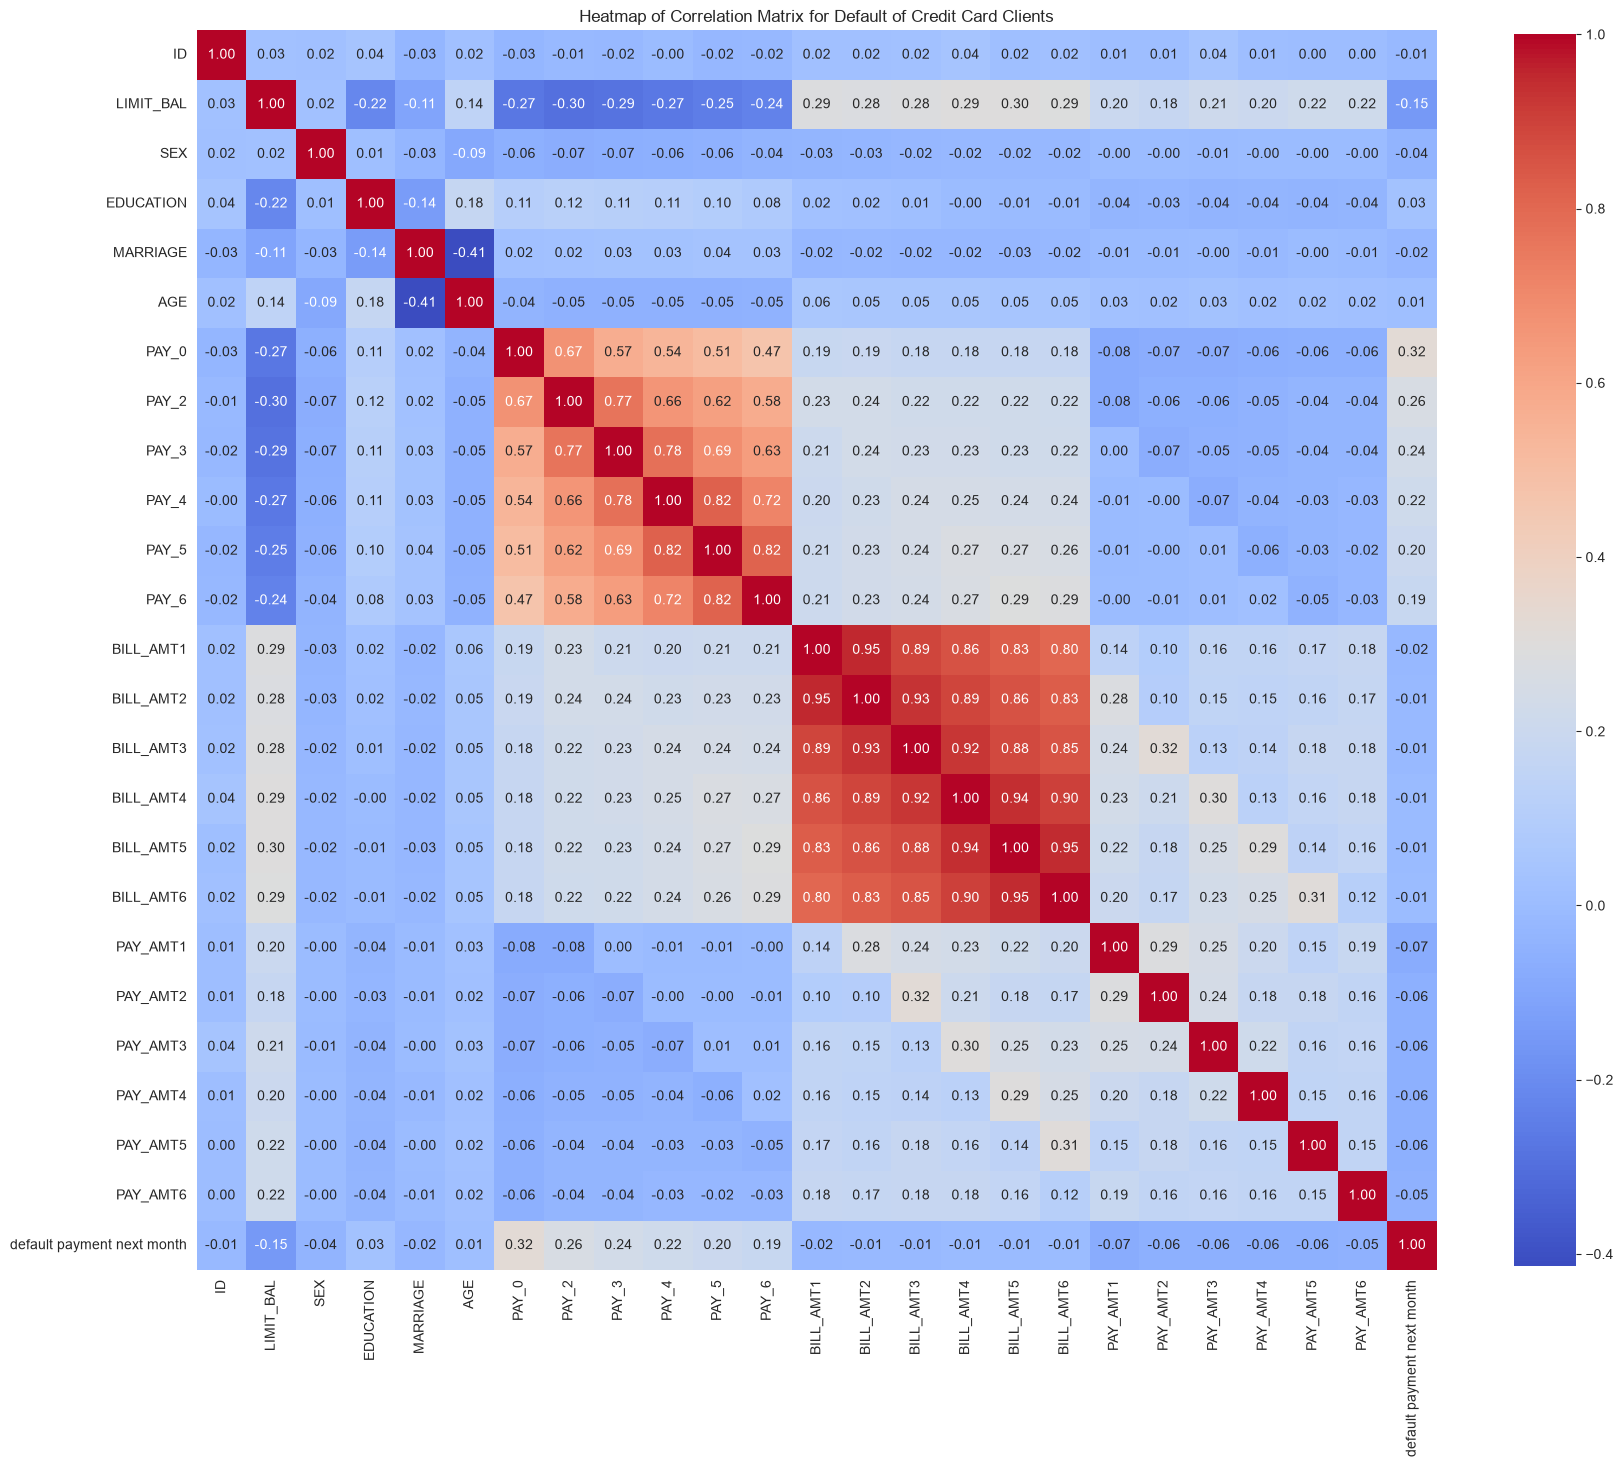

In [17]:
df_credit_card  = df.select_dtypes(include=['float64', 'int64'])

correlation_matrix = df_credit_card.corr()

plt.figure(figsize = (20, 20))
sns.heatmap(correlation_matrix, annot = True, fmt = '.2f', cmap = 'coolwarm', square = True, cbar_kws = {"shrink": .8})
plt.title('Heatmap of Correlation Matrix for Default of Credit Card Clients')

plt.show()

### ⚙ Initial Pre-processing.

In [19]:
df = df.rename(columns={"default payment next month": "label"})

In [21]:
X = df.loc[:, ~df.columns.isin(['ID','SEX', 'EDUCATION', 'MARRIAGE', 'label'])]
y = df['label']

In [22]:
X.shape
y.shape

(30000,)

## Second Semester:

**🤷🏾‍♂️ What will I do?**
* **Feature Engineering**
* **Predictive Modeling (Random Forest and XGBoost)**
* **Hyperparameter Tuning (`GridSearchCV`)**
* **Metric Evaluation (Recall, ROC-AUC)**
* **Dashboard Development**
* **Final Writing of the Capstone Report.**

### 🛠 Data Cleaning and Transformation 

In this step, we correct the issues identified during EDA. This includes handling missing values ​​(for example, by removing the corresponding rows), ensuring the data is in the correct format, and applying the function.

**Create a list of all columns with a ratio above 55% relative to the  [ default payment next month ] column [ if it exists ].**

In [18]:
# correlation = df.corr(numeric_only=True)

# corr_list = []

# for column, value in zip(
#     correlation.columns,
#     correlation["default payment next month"].sort_values(ascending=False)
# ):
#     print(value)
#     # if value >= 0.55 and column not in ["ID", "default payment next month"]:
#     #     corr_list.append(column)

In [20]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'label'],
      dtype='str')

### ✂ Splitting into Training and Test Data

An essential step for model training and evaluation. We split the dataset into two parts: a larger one (training), which the model uses to learn, and a smaller one (test), which is kept "hidden" from the model to simulate new data and evaluate its actual performance after training.

**As stated in the document, the data needs to be split into the following formats [ 5%, 15%, and 25% ], so we will use a function to avoid code duplication.**

In [23]:
def splittint_data(data:pd.DataFrame, label:pd.DataFrame, _test_size:float = 0.30, _random_state:int = 1, ):
    print(\
        f"""
             X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape
        """)
    return train_test_split(data, label, test_size = _test_size, random_state = _random_state, stratify=label)

### 👨🏽‍🔬 Predictive Modeling Pipeline

Here, we build an automated production pipeline for our model. The Scikit-learn Pipeline encapsulates all preprocessing stepS and the final model (Supervised Classification Models), ensuring that the same steps are consistently applied to both the training data and new data.


**Initially, we will use the three models below.**

* [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
* [Decision Tree](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
* [Xgboost](https://xgboost.readthedocs.io/en/stable/parameter.html)

#### Building Xgboost Model

In [24]:
import xgboost as xgb

#### Building Decision Tree Model

In [25]:
from sklearn.tree import DecisionTreeClassifier

In [26]:
# clf = DecisionTreeClassifier(criterion='gini', max_depth = 4, random_state = 0)

# # Train Decision Tree Classifer
# clf = clf.fit(X_train, y_train)

# #Predict the response for test dataset
# y_pred = clf.predict(X_test)

In [27]:
# # Model Accuracy, how often is the classifier correct?
# print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# # Rounded upto 2 decimal places
# print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

In [28]:
# # Predict by using an object classifier 'clf'
# y_predict = clf.predict(X_test)

# # Calculate cm by using a method named as 'confusion_matrix'
# cm = confusion_matrix(y_test, y_predict)

# # Plot confusion matrix with integers using seaborn heatmap
# plt.figure(figsize=(6, 4))
# sns.heatmap(cm, annot=True, fmt='d')  # 'd' stands for integer format
# plt.xlabel('Predicted labels')
# plt.ylabel('True labels')
# plt.title('Confusion Matrix')
# plt.show()

# # Generate classification report
# report = classification_report(y_test, y_predict)
# print("Classification Report:")
# print(report)

In [29]:
# **3 Splits de Treino (5%, 15% e 25%):**

In [30]:
# from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# # Confusion Matrix
# cm = confusion_matrix(y_test, y_pred)
# disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class 0", "Class 1"])
# disp.plot(cmap="Blues")
# plt.title(f"Confusion Matrix (k={best_k})")
# plt.grid(False)
# plt.show()

# # Detailed classification report
# print("Classification Report:")
# print(classification_report(y_test, y_pred, target_names=["Class 0", "Class 1"]))

#### Building Random Forest Model

In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification

In [32]:
from sklearn.ensemble import RandomForestClassifier

X, y = make_classification(
    n_samples = 1000,
    n_features = 4,
    n_informative = 2,
    n_redundant = 0,
    random_state = 0,
    shuffle = False
)

clf = RandomForestClassifier(max_depth=2, random_state=0)
clf.fit(X, y)

clf.predict([[0, 0, 0, 0]])

array([1])

### 👨🏽‍🔬 Model Evaluation and Metric Interpretation

### 👨🏽‍🏫 Final Writing of the Capstone Report.